# 03 · Exploratory Analysis

Univariate, bivariate and multivariate analysis, outliers, time series, products, geography and delivery.

> Data: Olist Brazilian E-Commerce public dataset (BRL). All narrative under charts is generated from the computed statistics.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
from src.analytics import eda
om, items, cm, daily = eda.load()

def show(f):
    if f.figure: display(Image(filename=str(ROOT / f.figure)))
    display(Markdown(f"**Business interpretation – {f.title}:** {f.interpretation}"))


## Univariate

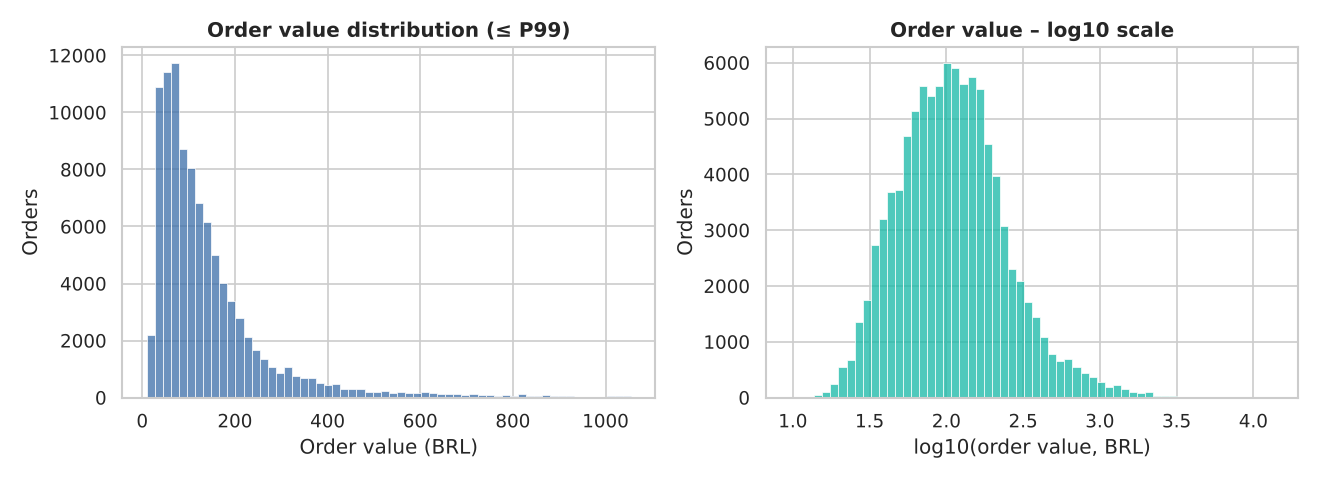

**Business interpretation – Order value distribution:** Order values are strongly right-skewed (skew 9.3): median R$ 105.28 vs mean R$ 160.24; 10% of orders exceed R$ 307. Use medians and log-scales for reporting; averages are pulled up by a long tail of high-ticket orders.

In [2]:
show(eda.univariate_order_value(om))

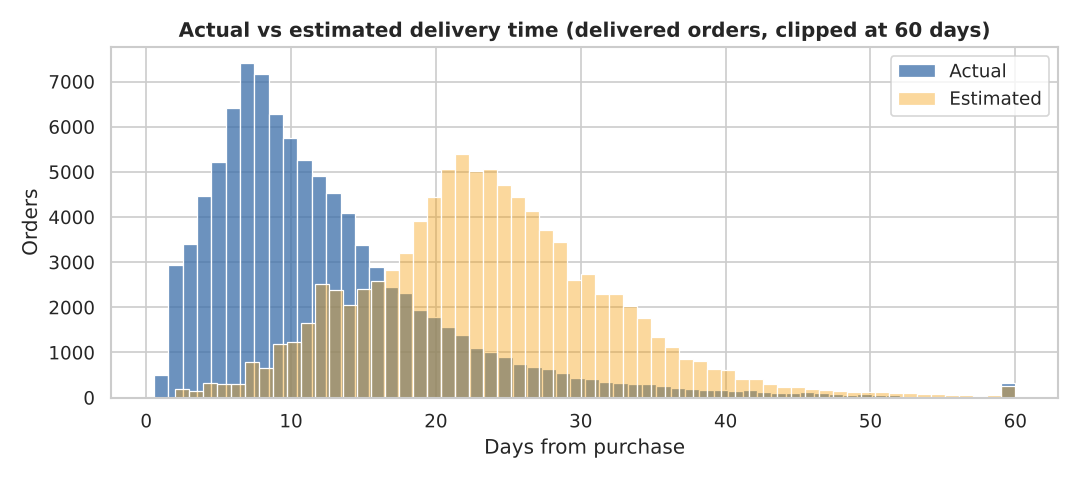

**Business interpretation – Delivery time vs estimate:** Median delivery takes 10.2 days against a median promise of 23.2 days, so 93.2% of orders arrive on or before the estimate. Estimates are padded by roughly 13 days – reliable, but long promised lead times may cost conversion.

In [3]:
show(eda.univariate_delivery(om))

## Bivariate

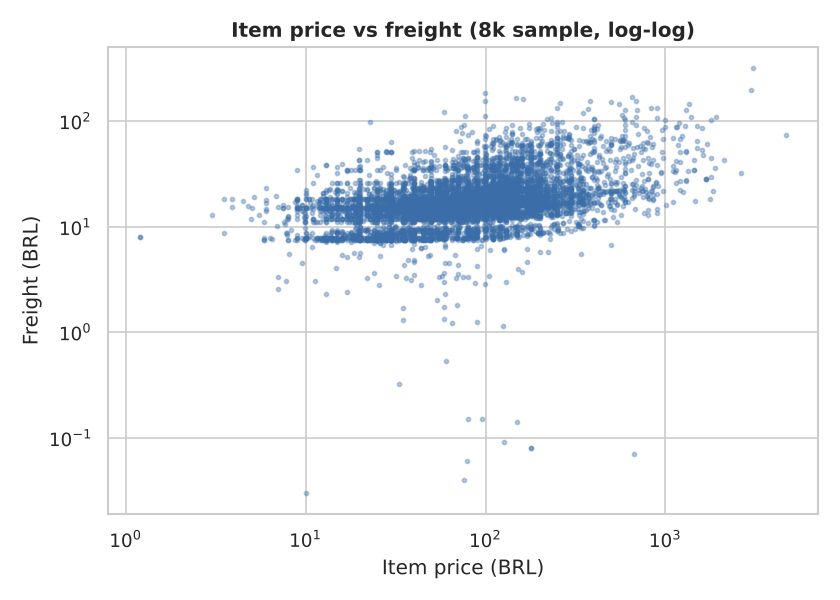

**Business interpretation – Price vs freight:** Freight rises with price (Spearman ρ = 0.43, p < 0.001) but far less than proportionally: the median item pays freight worth 23% of its price, and on 3.7% of items freight exceeds the price itself – a conversion risk for cheap items.

In [4]:
show(eda.bivariate_price_freight(items))

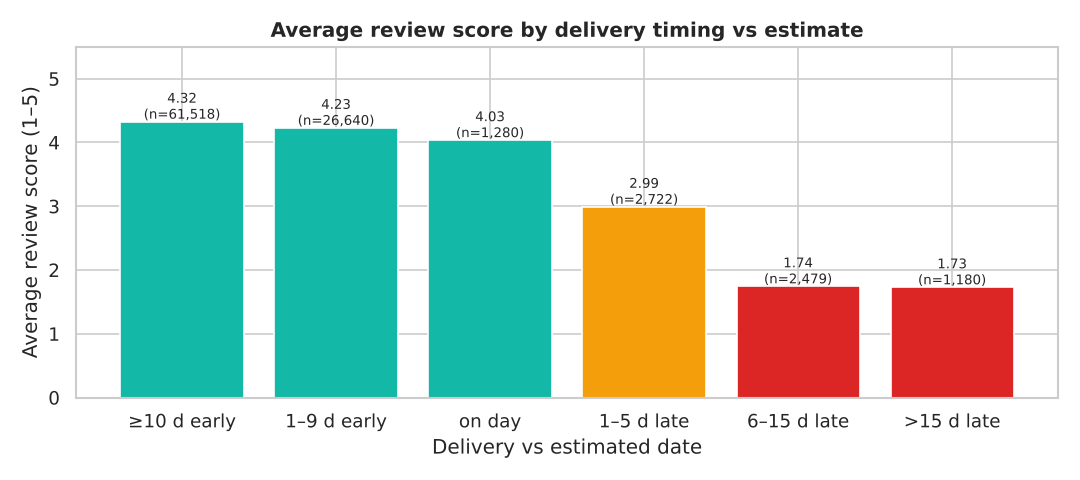

**Business interpretation – Delivery delay vs satisfaction:** On-time orders average 4.29 stars versus 2.27 for late orders – a gap of 2.02 points. Orders more than 15 days late average 1.73. Lateness is the most visible driver of dissatisfaction in the data (association; see hypothesis test H1).

In [5]:
show(eda.bivariate_delay_review(om))

## Multivariate

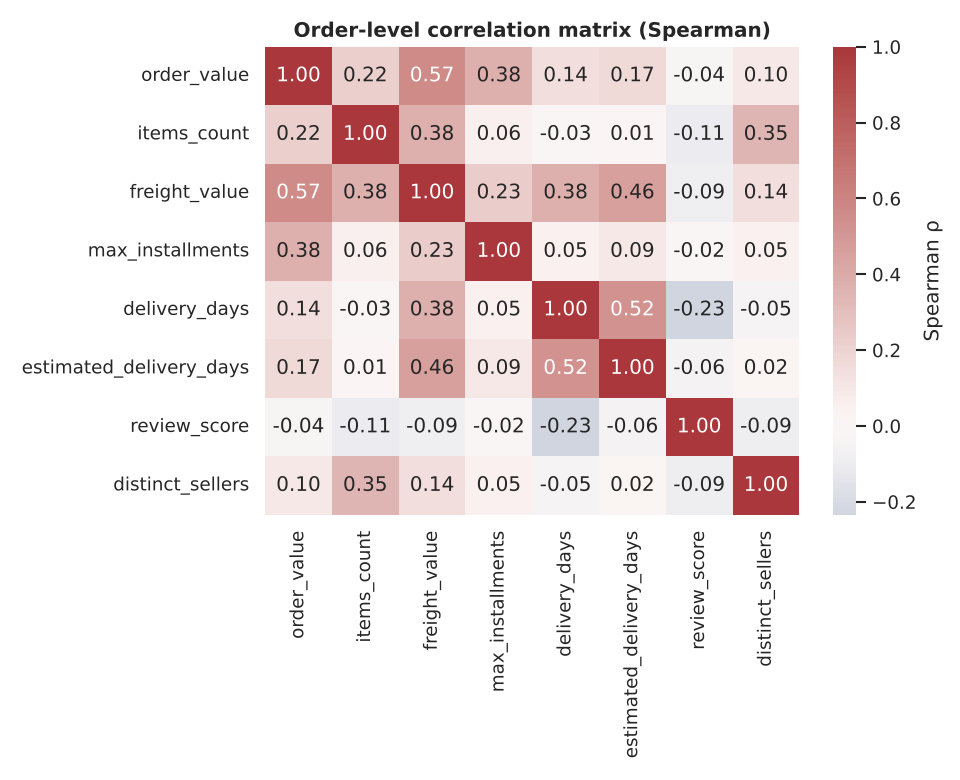

**Business interpretation – Multivariate correlation:** Strongest associations: order_value ~ freight_value (ρ=0.57); delivery_days ~ estimated_delivery_days (ρ=0.52); freight_value ~ estimated_delivery_days (ρ=0.46); freight_value ~ delivery_days (ρ=0.38). Review score correlates negatively with delivery days (ρ=-0.23) and only weakly with order value – customers judge logistics more than price.

In [6]:
show(eda.multivariate_correlation(om))

## Outliers

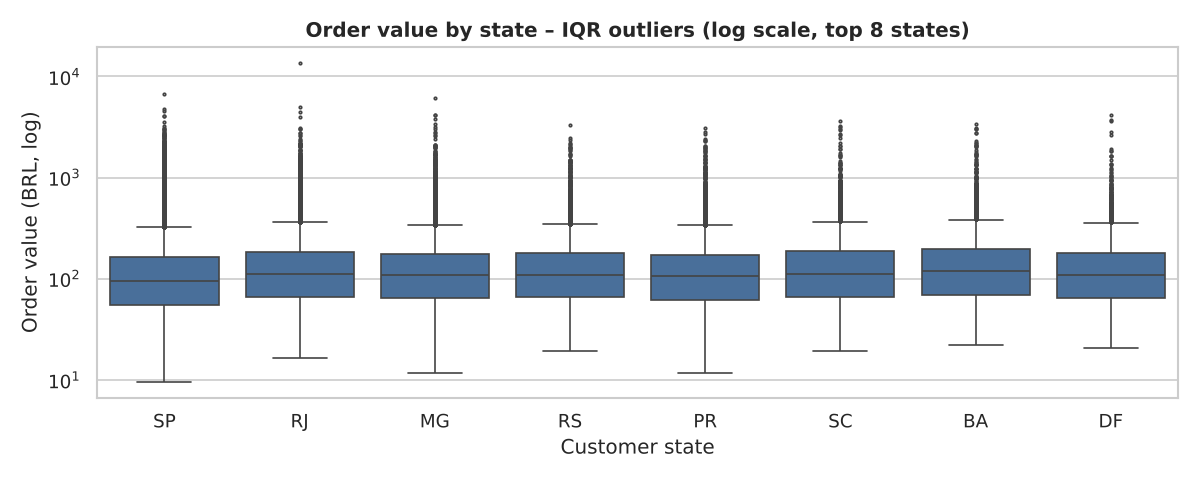

**Business interpretation – Order-value outliers:** 7,734 orders (7.9%) exceed the IQR fence of R$ 349, yet they carry 33.8% of revenue. They are legitimate high-ticket purchases, not errors – keep them, but use robust statistics (median, trimmed means) for typical-customer KPIs.

In [7]:
show(eda.outliers_order_value(om))

## Time series

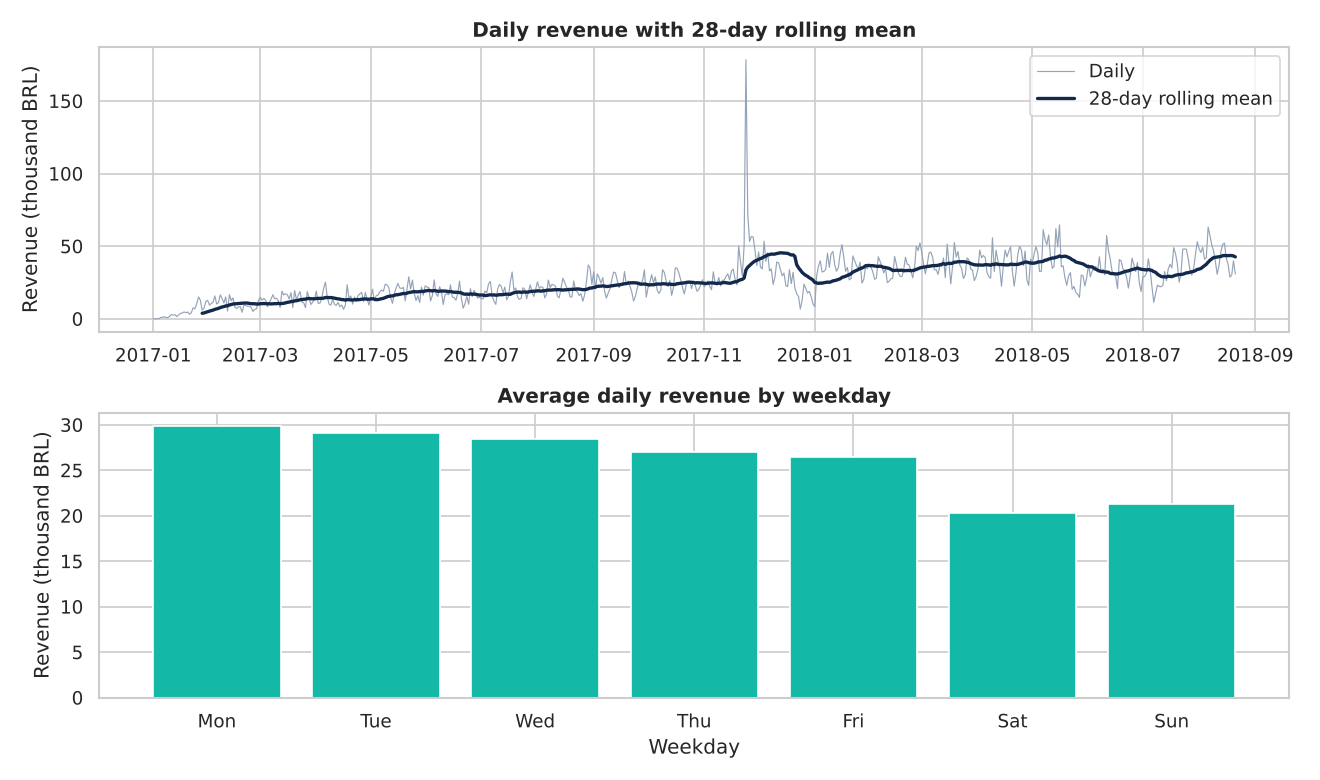

**Business interpretation – Revenue over time:** Revenue grew 140% Jan–Aug 2018 vs 2017 but plateaued from early 2018. The single biggest day was 2017-11-24 (Black Friday, R$ 178,378). Weekdays out-earn weekends; the weakest weekday averages 68% of the strongest.

In [8]:
show(eda.time_series_revenue(daily))

## Product performance

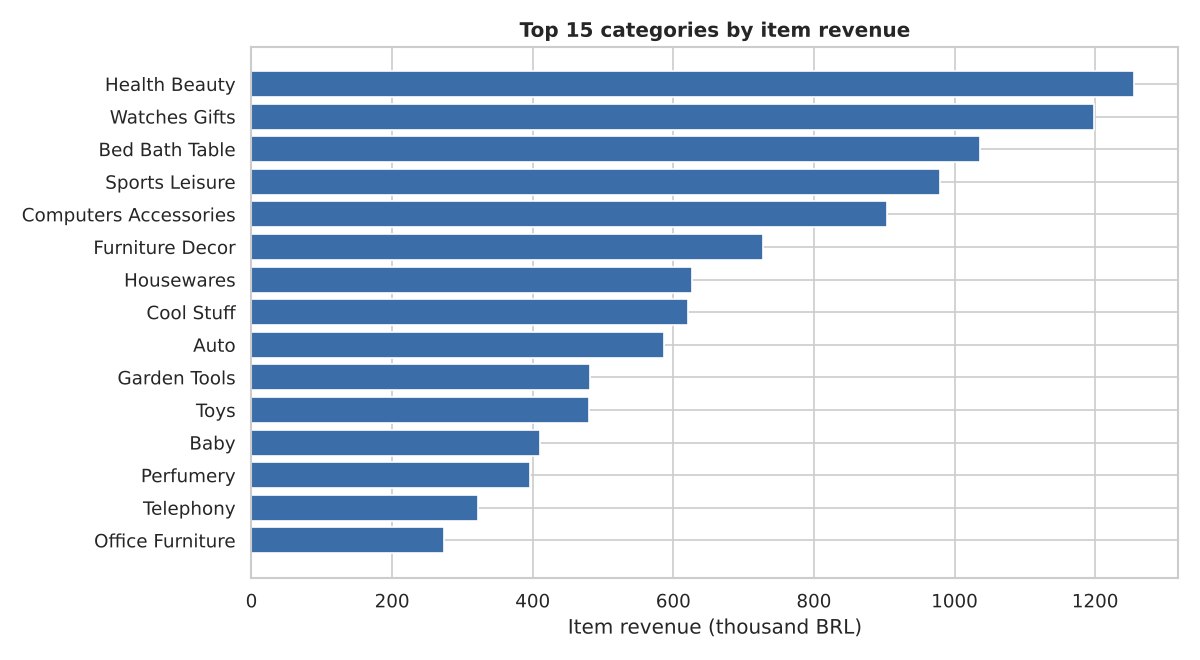

**Business interpretation – Product performance:** The top 10 of 74 categories generate 62% of item revenue; 'health beauty' leads. The catalogue is a long tail: 73% of products sold fewer than 3 units, so demand planning must happen at category, not SKU, level.

In [9]:
show(eda.product_performance(items))

## Geography

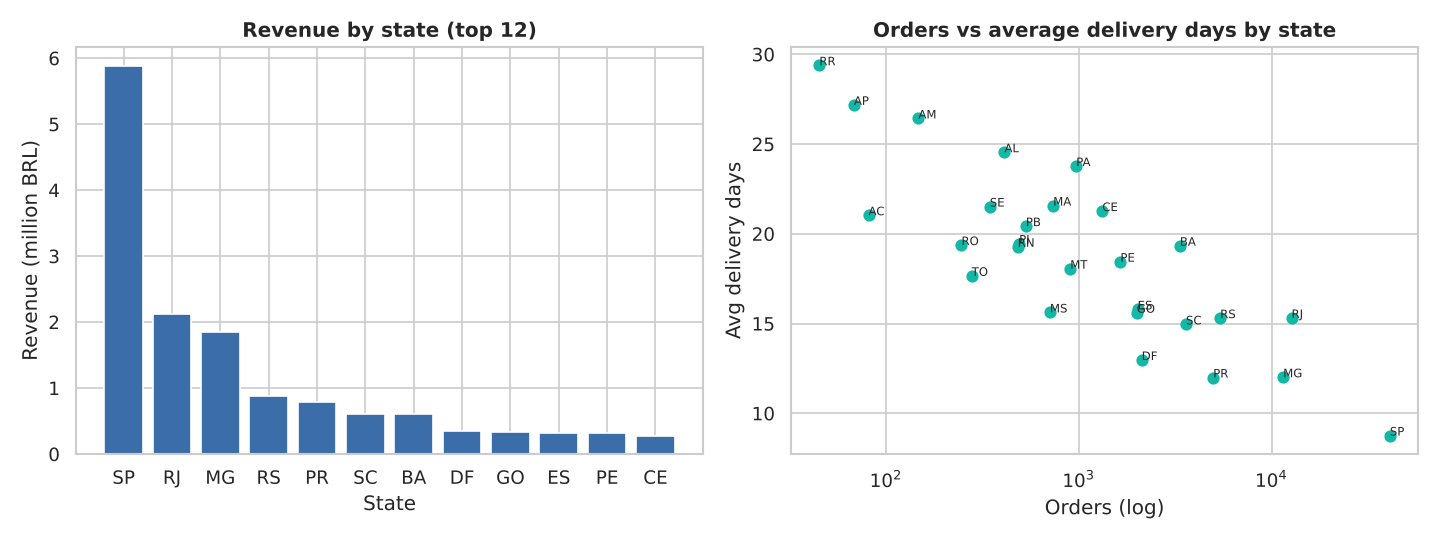

**Business interpretation – Geographic concentration:** São Paulo alone generates 37% of revenue and SP+RJ+MG 63%. SP orders arrive in 8.8 days on average versus 29.4 in RR. Because 71% of items ship from São Paulo sellers, delivery time grows with distance from SP, limiting growth in the North/Northeast.

In [10]:
show(eda.geographic(om))

## Delivery

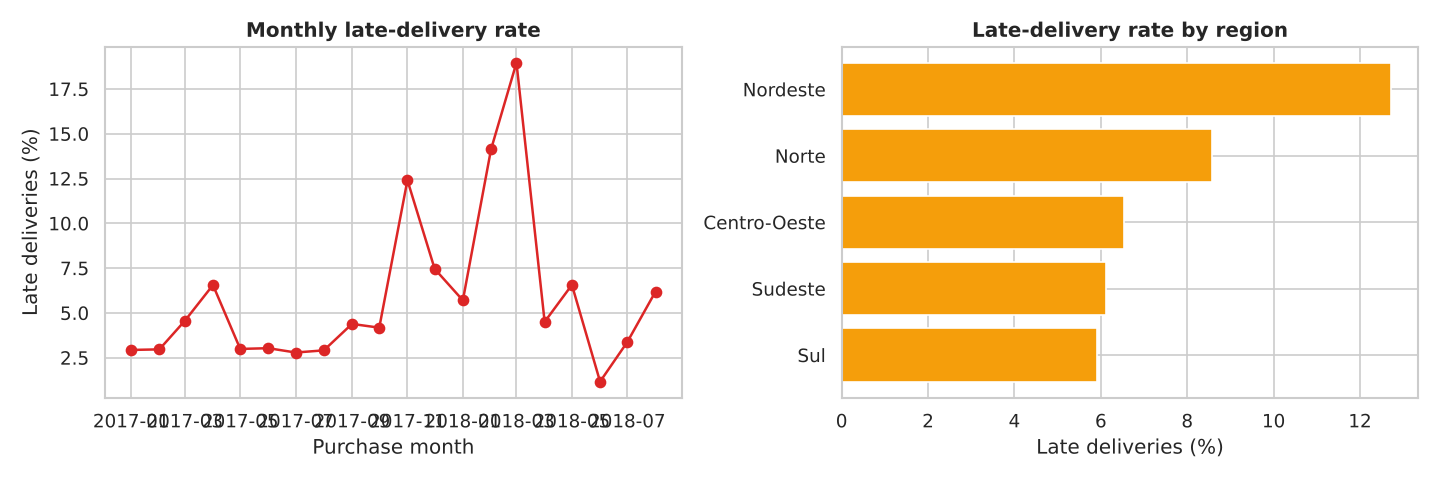

**Business interpretation – Late deliveries:** Late-delivery rates spike in a few months – 2018-03 (19.0%), 2018-02 (14.1%), 2017-11 (12.4%) – versus a monthly median of 4.4%, i.e. logistics capacity breaks under demand peaks (Nov-2017 = Black Friday). By region, Nordeste is late 12.7% of the time vs 5.9% in Sul.

In [11]:
show(eda.delivery_analysis(om))